# Отчет по Лабораторной работе №2
## Тема: Вывод символов на экран дисплея

**Студент:** ИУ5-35Б Штыка Денис Александрович
**Вариант:**
- Задание 1: S = "AMVtdiYVETHnNhuYwnWDVBqL"
- Задание 2: D = "+", N = 66, M = 6, K = 11
- Задание 4: N = 5277616985

**Сборка программ на fasm:** `fasm taskN.asm` и `ld taskN.o -o taskN.out`, запуск: `./taskN.out`.

**Как программа выводит символы:** вывод на экран выполняется системным вызовом `write` (`rax = 1`, `rdi = 1` для stdout, `rsi` указывает на данные, `rdx` задаёт число байт). Завершение программы выполняется вызовом `exit` (`rax = 60`).

## Задание 1
**Условие:** Разработать программу на языке ассемблера, которая выводит на экран заданную строку S в обратном порядке.

**Описание алгоритма:** длина строки вычисляется на этапе сборки (`len = $ - string`). Индекс в регистре `r13` уменьшается от последнего символа до нулевого, на каждом шаге адрес символа загружается в `rsi` командой `lea`, после чего выводится один байт. Индекс хранится в `r13`, потому что регистры `rsi` и `rdx` перезаписываются при подготовке вызова `write`.

Исходный код программы (`lab_2/task1/task1.asm`):

In [ ]:
format ELF64
public _start

section '.data' writable
    string db 'AMVtdiYVETHnNhuYwnWDVBqL'
    len = $ - string        ; длина строки (24)
    newline db 0x0A

section '.text' executable
_start:
    mov r13, len            ; r13 = 24
loop_rev:
    dec r13                 ; индекс 23, 22, ... 0
    lea rsi, [string + r13] ; адрес текущего символа
    mov rax, 1              ; sys_write
    mov rdi, 1              ; stdout
    mov rdx, 1              ; 1 байт
    syscall

    test r13, r13
    jnz loop_rev

    mov rax, 1              ; перевод строки
    mov rdi, 1
    mov rsi, newline
    mov rdx, 1
    syscall

    mov rax, 60             ; sys_exit
    xor rdi, rdi
    syscall

**Результат работы программы:**

![Результат задания 1](Screenshot_2026-11-09_at_11_18_14_PM.png)

## Задание 2
**Условие:** Разработать программу на языке ассемблера, в которой заполнить память N заданными символами, вывести их в виде матрицы по M символов в строке и K строк.

**Описание алгоритма:** в секции `.bss` резервируется буфер на N = 66 байт, который заполняется символом «+» командой `rep stosb`. Затем в цикле K = 11 раз выводится по M = 6 символов подряд из буфера, после каждой строки выводится перевод строки, а указатель сдвигается на 6 байт.

Исходный код программы (`lab_2/task2/task2.asm`):

In [ ]:
format ELF64
public _start

section '.data' writable
    newline db 0x0A

section '.bss' writable
    buf rb 66               ; N = 66 байт

section '.text' executable
_start:
    mov rdi, buf            ; заполняем память символом '+'
    mov al, '+'
    mov rcx, 66
    rep stosb

    mov r12, buf            ; указатель на начало текущей строки
    mov r13, 11             ; K = 11 строк
row_loop:
    mov rax, 1
    mov rdi, 1
    mov rsi, r12
    mov rdx, 6              ; M = 6 символов
    syscall

    mov rax, 1              ; перевод строки
    mov rdi, 1
    mov rsi, newline
    mov rdx, 1
    syscall

    add r12, 6              ; следующая строка в памяти
    dec r13
    jnz row_loop

    mov rax, 60
    xor rdi, rdi
    syscall

**Результат работы программы:**

![Screenshot 2026-09-24 at 3.25.16 PM.png](<attachment:Screenshot 2026-09-24 at 3.25.16 PM.png>)
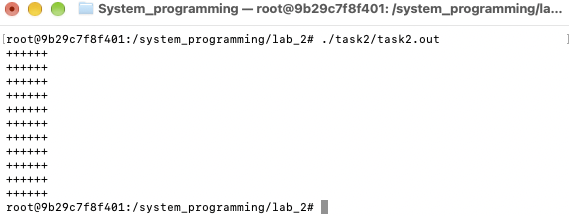

## Задание 3
**Условие:** В задании 2 вывести символы в виде треугольника.

**Описание алгоритма:** буфер заполняется так же, как в задании 2. Длина строки растёт на единицу (1, 2, 3, ...), каждая строка берётся из буфера с того места, где остановилась предыдущая. Так как 1 + 2 + … + 11 = 66, получается ровно 11 строк, и цикл завершается при выводе всех 66 символов.

Исходный код программы (`lab_2/task3/task3.asm`):

In [ ]:
format ELF64
public _start

section '.data' writable
    newline db 0x0A

section '.bss' writable
    buf rb 66

section '.text' executable
_start:
    mov rdi, buf
    mov al, '+'
    mov rcx, 66
    rep stosb

    xor r13, r13            ; сколько символов уже выведено (смещение в buf)
    xor r12, r12            ; длина текущей строки
tri_loop:
    inc r12                 ; 1, 2, 3, ...
    mov rax, 1
    mov rdi, 1
    lea rsi, [buf + r13]    ; продолжаем с того места, где остановились
    mov rdx, r12
    syscall

    add r13, r12

    mov rax, 1              ; перевод строки
    mov rdi, 1
    mov rsi, newline
    mov rdx, 1
    syscall

    cmp r13, 66
    jb tri_loop

    mov rax, 60
    xor rdi, rdi
    syscall

**Результат работы программы:**

![Screenshot 2026-09-24 at 3.26.04 PM.png](<attachment:Screenshot 2026-09-24 at 3.26.04 PM.png>)
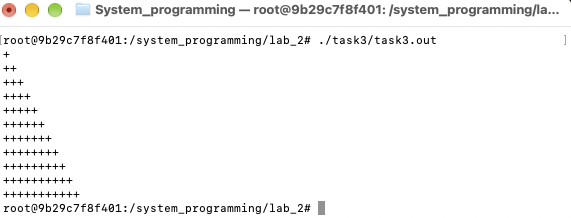

## Задание 4
**Условие:** Разработать программу на языке ассемблера, в которой для заданного числа N найти сумму его цифр и вывести результат на экран.

**Описание алгоритма:** команда `div rcx` делит `rdx:rax` на 10, остаток (последняя цифра) попадает в `rdx` и добавляется к сумме, а частное остаётся в `rax`. Цикл идёт, пока частное не станет нулём. Для числа 5277616985 сумма цифр равна 56. Затем сумма переводится в текст: цифры снова берутся делением на 10, к каждой прибавляется код `'0'` и она записывается в буфер `result_buf`. Так как цифры получаются с конца, выводятся они в обратном порядке.

Исходный код программы (`lab_2/task4/task4.asm`):

In [ ]:
format ELF64
public _start

section '.data' writable
    number dq 5277616985
    newline db 0x0A

section '.bss' writable
    result_buf rb 20            ; 20 байт под цифры результата

section '.text' executable
_start:
    mov rax, [number]
    xor rbx, rbx                ; rbx = сумма цифр
sum_loop:
    xor rdx, rdx
    mov rcx, 10
    div rcx                     ; rax = частное, rdx = последняя цифра
    add rbx, rdx
    test rax, rax
    jnz sum_loop

    mov rax, rbx                ; превращаем сумму в текст
    xor r8, r8                  ; r8 = сколько цифр получилось
convert_loop:
    xor rdx, rdx
    mov rcx, 10
    div rcx
    add dl, '0'                 ; цифра -> ASCII
    mov [result_buf + r8], dl
    inc r8
    test rax, rax
    jnz convert_loop

    mov r9, r8
    dec r9                      ; цифры лежат задом наперёд, печатаем с конца
print_loop:
    lea rsi, [result_buf + r9]
    mov rax, 1                  ; sys_write
    mov rdi, 1                  ; stdout
    mov rdx, 1
    syscall
    dec r9
    jge print_loop              ; пока r9 >= 0

    mov rax, 1                  ; перевод строки
    mov rdi, 1
    mov rsi, newline
    mov rdx, 1
    syscall

    mov rax, 60                 ; sys_exit
    xor rdi, rdi
    syscall

**Результат работы программы:**

![Screenshot 2026-09-24 at 3.26.43 PM.png](<attachment:Screenshot 2026-09-24 at 3.26.43 PM.png>)
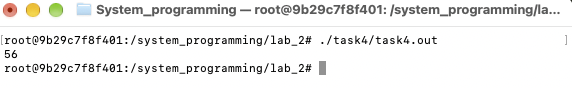

## Задание 5
**Условие:** Разработать программу аналогичную заданию 4 на языке программирования C. Провести сравнение размеров исполняемых файлов.

Исходный код программы (`lab_2/task5/task5.c`):

In [ ]:
#include <stdio.h>

int main() {
    unsigned long long n = 5277616985ULL;
    unsigned long long sum = 0;
    while (n > 0) {
        sum += n % 10;
        n /= 10;
    }
    printf("%llu\n", sum);
    return 0;
}

**Результат работы программы:**

![Результат задания 5](<Screenshot 2026-09-24 at 3.27.28 PM.png>)

**Сравнение размеров исполняемых файлов:**

Сборка программ:
```
ld task4.o -o task4.out            # asm, обычная сборка
ld -N -s task4.o -o task4_small.out # asm, сокращённый размер
gcc task5.c -o task5                # C, обычная сборка
gcc -Os -s task5.c -o task5_small   # C, сокращённый размер
```

| Программа | Обычная сборка | Сокращённый размер |
|---|---|---|
| Ассемблер (fasm + ld) | 8848 байт | 640 байт |
| C (gcc) | 15960 байт | 14472 байт |

Все четыре варианта выводят результат 56.

![Сборка и размеры файлов](Screenshot_2026-11-09_at_11_25_28_PM.png)

**Как сокращался размер:**
- Для программы на ассемблере ключ `-s` убирает таблицу символов, а `-N` отключает выравнивание сегментов по границе страницы (4096 байт). Размер сократился с 8848 до 640 байт, то есть примерно в 14 раз.
- Для программы на C ключ `-Os` включает оптимизацию по размеру, а `-s` убирает таблицу символов. Размер сократился с 15960 до 14472 байт, примерно на 9 %.

**Вывод:** Исполняемый файл на языке ассемблера значительно меньше, так как он не содержит стандартных библиотек языка C и содержит только минимально необходимый машинный код. Программа на C подключает стандартную библиотеку и вызывает `printf`, поэтому даже после оптимизации её файл остаётся в десятки раз больше, чем сокращённый файл на ассемблере (14472 против 640 байт).